<a href="https://colab.research.google.com/github/EnesKok20/cepte-vet/blob/main/notebooks/03_kaggle_veri_seti.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

ANA = '/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik'
RAW = ANA + '/raw'
!ls -lh "{RAW}"

Mounted at /content/drive
total 411M
-rw------- 1 root root 257M Oct 13 11:01  archive.zip
-rw------- 1 root root 155M Oct 13 06:42 'Lumpy Skin Images Dataset.zip'


In [2]:
!mkdir -p /content/data/kaggle
!unzip -q "{RAW}/KAGGLE_ZIP_ADI.zip" -d /content/data/kaggle

unzip:  cannot find or open /content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/raw/KAGGLE_ZIP_ADI.zip, /content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/raw/KAGGLE_ZIP_ADI.zip.zip or /content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/raw/KAGGLE_ZIP_ADI.zip.ZIP.


In [3]:
import os
VERI = '/content/data/kaggle'
for klasor, alt_klasorler, dosyalar in os.walk(VERI):
    resimler = [d for d in dosyalar if d.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if resimler:
        print(klasor.replace(VERI, ''), '->', len(resimler), 'görüntü')

In [5]:
!find /content/data/kaggle -maxdepth 3 -type d
!echo "-----"
!find /content/data/kaggle -type f | head -10

/content/data/kaggle
-----


In [6]:
!ls -lh "{RAW}"

total 411M
-rw------- 1 root root 257M Oct 13 11:01  archive.zip
-rw------- 1 root root 155M Oct 13 06:42 'Lumpy Skin Images Dataset.zip'


/Cows datasets/healthy -> 1291 görüntü
/Cows datasets/foot-and-mouth -> 746 görüntü
/Cows datasets/lumpy -> 1207 görüntü


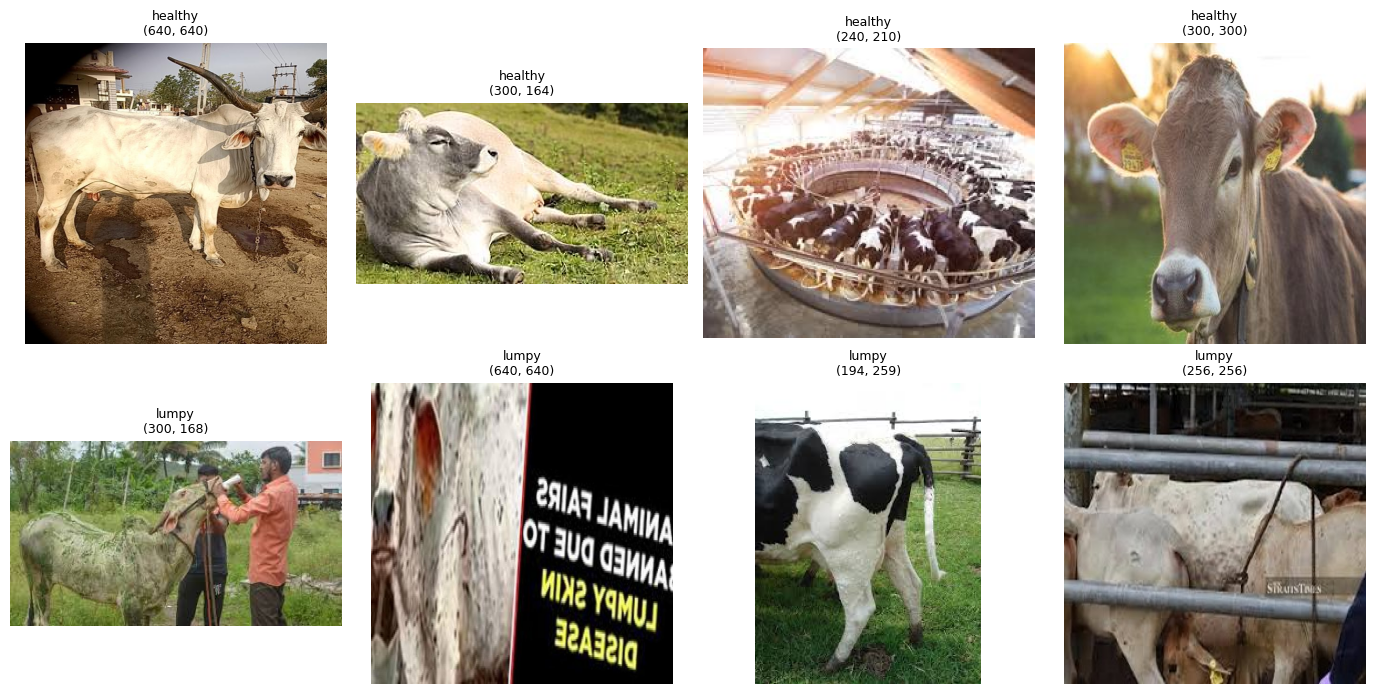

In [7]:
import os, glob, random
import matplotlib.pyplot as plt
from PIL import Image

RAW = '/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/raw'
VERI = '/content/data/kaggle'
UZANTILAR = ('.png', '.jpg', '.jpeg', '.webp', '.bmp')

# 1) Zip'i aç
!mkdir -p {VERI}
!unzip -q -o "{RAW}/archive.zip" -d {VERI}

# 2) Her klasördeki görüntüleri say
siniflar = {}
for klasor, alt_klasorler, dosyalar in os.walk(VERI):
    resimler = [os.path.join(klasor, d) for d in dosyalar if d.lower().endswith(UZANTILAR)]
    if resimler:
        ad = os.path.basename(klasor)
        siniflar[ad] = resimler
        print(f'{klasor.replace(VERI, "")} -> {len(resimler)} görüntü')

# 3) lumpy ve healthy'den 4'er görüntü göster
gosterilecek = [ad for ad in siniflar if ad.lower() in ('lumpy', 'healthy')]
fig, eksenler = plt.subplots(len(gosterilecek), 4, figsize=(14, 3.5 * len(gosterilecek)), squeeze=False)
for satir, ad in enumerate(gosterilecek):
    secilen = random.sample(siniflar[ad], min(4, len(siniflar[ad])))
    for sutun, yol in enumerate(secilen):
        resim = Image.open(yol)
        eksenler[satir, sutun].imshow(resim)
        eksenler[satir, sutun].set_title(f'{ad}\n{resim.size}', fontsize=9)
        eksenler[satir, sutun].axis('off')
plt.tight_layout()
plt.show()